In [ ]:
'''objetivos:
comparar resposta ao ruído para FF de 0.1 a 40% usando os métodos:
dixon
multieco 3 pontos
multi-interferência 7 pontos
ann

materiais e métodos
datasets de teste:
FF: 1% a 40%, step de 1% (40 steps), randomizado uniforme, 10 iterações por step
T2* 0.9, 1.3, 2.1 ppm randomizados na gaussiana limitados entre 0 e 1
T2* 4.2 e 5.3 ppm fixos
T2* 4.7 (agua) ppm randomizado na gaussiana limitado entre 0 e 1
ruído randomizado adicionado em relação ao primeiro ponto:
teste com SNR = 200
teste com SNR = 100
teste com SNR = 50
teste com SNR = 25

dataset de treino do ann:
dataset padrão
FF: 1% a 100%, step de 0.1% (1000 steps), linear, 50 iterações por step
T2* 0.9, 1.3, 2.1 ppm randomizados na gaussiana limitados entre 0 e 1
T2* 4.2 e 5.3 ppm fixos
T2* 4.7 (agua) ppm randomizado na gaussiana limitado entre 0 e 1
ruído randomizado uniforme adicionado em relação ao primeiro ponto:
SNR [200 25]

MÉTRICAS
standard deviation of the pairwise difference and correlation coefficient between real and estimation
sensitivity, specificity 
	(threshold 6.25%? 
	two-sided confidence intervals 95%?
	bias-corrected and accelerated intervals from bootstrap distribution of 1000 resampled datasets?
	thresholds 5,6,7,8%?)
regression slopes and intercepts
	null hypostesis: slope 1, intercept 0
	two-tailed t test, alpha=0.05
'''

In [1]:
#bibliotecas e funções para gerar o dataset

# INICIALIZAÇÃO DAS BIBLIOTECAS
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from scipy.optimize import curve_fit
from scipy.stats import truncnorm
import itertools
import statsmodels.formula.api as smf
import numpy as np
import pandas

####### FUNÇÕES PARA OBTENÇÃO DO SINAL ######

def get_truncated_normal(mean=0, sd=1, low=0, upp=10):
    return(truncnorm((low - mean) / sd, (upp - mean) / sd, loc=mean, scale=sd))

def set_random_rho(ff):
    '''
    Returns the Proton Density values rho_fat, rho_water for a given Fat fraction ff
    parameters: ff     -> float 0>1 fat fraction
    returns:    rho_fat, rho_water
    '''
    rho_fat = np.random.rand()
    rho_water = (rho_fat/ff)-rho_fat
    return(rho_fat, rho_water)

def discrete_timeseries(n_echoes):
    '''
    This function calculates the echo times for n_echoes in the GRE IP-OP sequence, considering TE = 0.0011515, 
    which corresponds to water (4.7 ppm) and fat (1.3 ppm) interference at 3 Tesla.
    parameters: n_echoes     -> integer >0, number of equally spaced echoes
    returns:    echo_times
     '''
    # TE acquisition times for n echoes
    echo_times = np.linspace(0.0011515, 0.0011515*n_echoes, n_echoes, endpoint=True)
    return(echo_times)

def gen_GRE_noise(echo_times, rho_fat, rho_water, t2fat09=0.083, t2fat13=0.061, t2fat21=0.052, t2fat275=0.051, 
                  t2fat42=0.0254, t2fat53=0.0387, t2water47=0.027, noise_level=0.00):
    '''
    This function calculates the GRE IP-OP signal from human liver, for any number of TEs,
    considering a low flip angle (Taylor approx. around zero) and 3T.
    It is based on studies by Hamilton (T2* and characteristic ppm frequency values).
    parameters: echo times -> array with TEs
                rho_fat    -> float >0, fat proton density
                rho_water  -> float >0, water proton density
                t2star     -> array >0, T2* values for fat peaks at 0.9, 1.3., 2.1, 2.75, 4.2 and 5.3ppm (fat) and 
                                        water at 4.7 ppm. Standard values are [0.030, 0.040, 0.051, 0.052, 0.062, 0.083, 0.023]
                noise_sd   -> float >0, noise level (1/SNR) as proportion of the first signal point intensity 
                                        (default is 0%)
    returns:    Sabs -> float > 0, absolute signal intensity in arbitrary units (equivalent to ydata)
    '''
# rho_fat is a general variable that multiplies intrinsic fat constants (Hamilton)
    rho = np.array([rho_fat*0.088, rho_fat*0.7, rho_fat*0.12, rho_fat*0.006, rho_fat*0.039, rho_fat*0.047, rho_water])
    
    # individual T2* values
    t2star = np.array([t2fat09, t2fat13, t2fat21, t2fat275, t2fat42, t2fat53, t2water47])
    
    # frequency in parts per million for each moiety
    freq_ppm = np.array([0.9, 1.3, 2.1, 2.75, 4.2, 5.3, 4.7])
    
    freq = np.zeros(len(freq_ppm))
    magField = np.array(3.0)      # magnetic field, Tesla (if change, remember to change echo spacing)
    hydroGyro = np.array(42.57e6) # Hydrogen gyromagnetic ratio, Hz/T
    
    for n, fppm in enumerate(freq_ppm):
        freq[n] = fppm*magField*hydroGyro/1e6
    
    # calculate the complex signal for each moiety    
    S = (len(freq_ppm),len(echo_times))
    S = np.zeros(S,dtype='complex')
    
    for n, moieties in enumerate(freq_ppm):
        for t,TE in enumerate(echo_times):
            S[n,t] = rho[n]*np.exp(-TE/t2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE)         
        
    #obtain sum & add noise
    Ssum = (len(echo_times))
    Ssum = np.zeros(Ssum,dtype='complex')
    Ssum = np.sum(S, axis=0)
    
    for t,TE in enumerate(echo_times):
        Ssum[t] = Ssum[t].real+Ssum[0].real*noise_level*np.random.normal()+1j*(Ssum[t].imag+Ssum[0].imag*noise_level*np.random.normal())
 
    #obtain absolute value
    Sabs = (len(echo_times))
    Sabs = np.zeros(Sabs,dtype='complex')
    Sabs = np.absolute(Ssum)
    return(Sabs)

In [2]:
#bibliotecas e funções para métodos de estimação

################################## MULTI-INTERFERENCIA ##################################

def fit_multiinterf(echo_times, rho_fat, rho_water, t2star):
    '''
    This function fits the GRE IP-OP signal from human liver, for any number of TEs,
    considering a low flip angle (Taylor approx. around zero) and 3T.
    It is based on studies by Hamilton (T2* and characteristic ppm frequency values).
    parameters: echo times -> array with TEs
                rho_fat    -> float >0, fat proton density
                rho_water  -> float >0, water proton density
    returns:    Sabs -> float > 0, absolute signal intensity in arbitrary units (equivalent to ydata)
    '''
    
    echo_times = np.array(echo_times)
    rho_fat = np.array(rho_fat)
    rho_water = np.array(rho_water)
    t2star = np.array(t2star)
    
    #cn is the fractional proton density of each fat moiety (Yokoo) (see freq_ppm)
    cn = np.array([0.12, 0.7, 0.088,]) 
    
    #frequency in parts per million for each fat moiety
    ppm_fat = np.array([2.1, 1.3, 0.9])
    ppm_water = np.array(4.7)
    
    magField = np.array(3.0) #magnetic field, Tesla (if change, remember to change echo spacing)
    hydroGyro = np.array(42.577e6) #Hydrogen gyromagnetic ratio, Hz/T
    freq_water = np.array(ppm_water*magField*hydroGyro/1e6) #water frequency in Hertz
    
    #relative frequency for each fat to that of water
    freqr_fat = np.zeros(len(ppm_fat))
    for n, fppm in enumerate(ppm_fat):
        freqr_fat[n] = freq_water-(fppm*magField*hydroGyro/1e6)
    
    #calculate the signal for each moiety    
    S = (len(freqr_fat),len(echo_times))
    S = np.zeros(S,dtype='complex')
        #three fat signals
    for n, moieties in enumerate(freqr_fat):
        for t,TE in enumerate(echo_times):
            S[n,t] = cn[n]*np.exp(2.0*np.pi*1j*freqr_fat[n]*TE)
    
    Ssum= len(echo_times)
    Ssum = np.zeros(Ssum)
    Ssum = np.sum(S, axis=0) #sum of fat signals
    Sabs = np.absolute(rho_water + rho_fat*Ssum) #multiply rho_fat and add rho_water, take absolute value
    Sfinal = len(echo_times)
    Sfinal = np.zeros(Sfinal)
    for t,TE in enumerate(echo_times):
        Sfinal[t] = Sabs[t]*np.exp(-TE/t2star) #exponential decay
    
    return(Sfinal)

################################## TRIPLE-ECHOE ##################################

def fit_tripleEcho(echo_times, voxelSignal):
    '''
    this function calculates the fat fraction according to corrected Dixon's method, which considers a single T2* effect.
    parameters: voxelSignal -> array, float >0, signal intensities, at least two values.
    returns:    fat_fraction -> float
    '''
    s1 = voxelSignal[0]
    s2 = voxelSignal[1]
    s4 = voxelSignal[3]
    deltaTE = echo_times[1]-echo_times[0]
    t2star = deltaTE/np.log(s2/s4)
    
    rho_water = (s2 * np.exp(echo_times[1]/t2star) + s1* np.exp(echo_times[0]/t2star))/2
    rho_fat = (s2 * np.exp(echo_times[1]/t2star) - s1* np.exp(echo_times[0]/t2star))/2

    return(rho_fat, rho_water)

################################## DIXON ##################################

def fit_dixon(voxelSignal):
    '''
    this function calculates the fat fraction according to Dixon's method.
    parameters: voxelSignal -> array, float >0, signal intensities, at least two values.
    returns:    fat_fraction -> float
    '''
    s1 = voxelSignal[0]
    s2 = voxelSignal[1]
    rho_water = (s2 + s1)/2
    rho_fat = (s2 - s1)/2
    return(rho_fat, rho_water)

################################## CALC_FATFRAC ##################################

def calc_fatfrac(fitted_parameters):
    '''
    Returns the Fat Fraction ff  for values rho_fat (fitted_parameters[0]) and rho_water (fitted_parameters[1])
    parameters: fitted parameters -> list or tuple, where rho_fat = fitted_parameters[0] and rho_water fitted_parameters[1])
    returns:    ff - > fat fraction
    '''
    ff =  fitted_parameters[0] / (fitted_parameters[0] + fitted_parameters[1])
    return(ff)

In [3]:
def zona(snr):
    ############################################ SETTINGS ############################################
    total_size = 5000
    ff = np.random.uniform(0.01, 0.4, total_size) # fat fraction, limites, numero de discretizações
    ff_iterations = 1 #numero de iterações do mesmo valor de FF

    ############################################# CÓDIGO #############################################
    ###################################### parâmetros do sinal ######################################

    t2fat09 = get_truncated_normal(0.083, 0.0163, low=0.001, upp=1).rvs(total_size) #mean, sd, min, max (para não obter valor negativo)
    t2fat13 = get_truncated_normal(0.061, 0.0113, low=0.001, upp=1).rvs(total_size)
    t2fat21 = get_truncated_normal(0.052, 0.0298, low=0.001, upp=1).rvs(total_size)
    t2fat275 = np.repeat(0.051,total_size)
    t2fat42 = np.repeat(0.0254,total_size)
    t2fat53 = np.repeat(0.0387,total_size)
    t2water47 = get_truncated_normal(0.027, 0.0066, low=0.001, upp=1).rvs(total_size)

    noise_values = np.repeat(1/snr, total_size) #ruido (1/snr) minimo, maximo, numero de iter

    ######################################## inicialização dos arrays ########################################

    ff_repeat = np.repeat(ff,ff_iterations) #repete ff para preencher a lista

    signal_collection = np.zeros([total_size,7]) #sinal normalizado
    xdata = discrete_timeseries(7) #gerar TEs para 3T

    ############################################# gera as curvas #############################################
    n=0
    for fat_fraction in ff_repeat:
        rho_fat, rho_water = set_random_rho(fat_fraction) #obter rhos aleatorios que atendam a uma determinada FF
        signal = gen_GRE_noise(xdata, rho_fat, rho_water, t2fat09[n], t2fat13[n], t2fat21[n], 
                               t2fat275[n], t2fat42[n], t2fat53[n], t2water47[n], noise_values[n]) #obter sinal GRE
        signal_collection[n,:] = signal #colocar os sinais numa coleção, pontos 0:6
        n = n+1
    
    res_dixon = []
    res_tripl = []
    res_multi = []
    for ydata in signal_collection:
        p0 = (ydata[0]/2, ydata[1]/3)
        
        # DIXON
        par = fit_dixon(ydata)
        res_dixon.append(calc_fatfrac(par))
        
        # TRIPLE
        par = fit_tripleEcho(xdata, ydata)
        res_tripl.append(calc_fatfrac(par))
        
        # MULTI
        bd = (0, [np.inf,np.inf,1])
        fitted_par, pcov = curve_fit(fit_multiinterf, xdata, ydata, bounds=bd)
        res_multi.append(calc_fatfrac(fitted_par))
    
    return(ff, res_dixon, res_tripl, res_multi)

In [21]:
## -------------> SNR = 200 <------------- ##
snr_200 = 200

ff_200, res_dixon_200, res_tripl_200, res_multi_200 = zona(snr_200)

data = pandas.DataFrame({'ff_200' : ff_200, 'res_dixon_200' : res_dixon_200})
mod = smf.ols(formula='res_dixon_200 ~ ff_200', data=data)
res = mod.fit()
print(res.summary())

print('\n')
print('###################################################################################')
print('\n')

data = pandas.DataFrame({'ff_200' : ff_200, 'res_tripl_200' : res_tripl_200})
mod = smf.ols(formula='res_tripl_200 ~ ff_200', data=data)
res = mod.fit()
print(res.summary())

print('\n')
print('###################################################################################')
print('\n')

data = pandas.DataFrame({'ff_200' : ff_200, 'res_multi_200' : res_multi_200})
mod = smf.ols(formula='res_multi_200 ~ ff_200', data=data)
res = mod.fit()
print(res.summary())

                            OLS Regression Results                            
Dep. Variable:          res_dixon_200   R-squared:                       0.999
Model:                            OLS   Adj. R-squared:                  0.999
Method:                 Least Squares   F-statistic:                 8.265e+06
Date:                Fri, 10 Nov 2017   Prob (F-statistic):               0.00
Time:                        18:13:32   Log-Likelihood:                 23105.
No. Observations:                5000   AIC:                        -4.621e+04
Df Residuals:                    4998   BIC:                        -4.619e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0054   6.94e-05    -78.106      0.0

In [ ]:
## -------------> SNR = 100 <------------- ##
snr_100 = 100

ff_100, res_dixon_100, res_tripl_100, res_multi_100 = zona(snr_100)

In [ ]:
## -------------> SNR = 50 <------------- ##
snr_50 = 50

ff_50, res_dixon_50, res_tripl_50, res_multi_50 = zona(snr_50)

In [4]:
###################### -------------> SNR = 25 <------------- ######################
snr_25 = 25

ff_25, res_dixon_25, res_tripl_25, res_multi_25 = zona(snr_25)

                            OLS Regression Results                            
Dep. Variable:           res_dixon_25   R-squared:                       0.981
Model:                            OLS   Adj. R-squared:                  0.981
Method:                 Least Squares   F-statistic:                 2.561e+05
Date:                Fri, 10 Nov 2017   Prob (F-statistic):               0.00
Time:                        18:47:42   Log-Likelihood:                 13981.
No. Observations:                5000   AIC:                        -2.796e+04
Df Residuals:                    4998   BIC:                        -2.794e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0273      0.000    -63.111      0.0

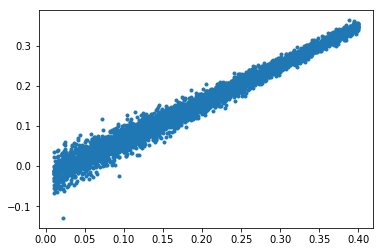



###################################################################################


                            OLS Regression Results                            
Dep. Variable:           res_tripl_25   R-squared:                       0.957
Model:                            OLS   Adj. R-squared:                  0.957
Method:                 Least Squares   F-statistic:                 1.107e+05
Date:                Fri, 10 Nov 2017   Prob (F-statistic):               0.00
Time:                        18:47:42   Log-Likelihood:                 12151.
No. Observations:                5000   AIC:                        -2.430e+04
Df Residuals:                    4998   BIC:                        -2.429e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------

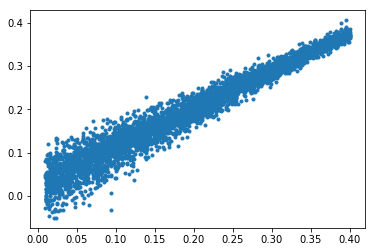



###################################################################################


                            OLS Regression Results                            
Dep. Variable:           res_multi_25   R-squared:                       0.989
Model:                            OLS   Adj. R-squared:                  0.989
Method:                 Least Squares   F-statistic:                 4.372e+05
Date:                Fri, 10 Nov 2017   Prob (F-statistic):               0.00
Time:                        18:47:43   Log-Likelihood:                 14767.
No. Observations:                5000   AIC:                        -2.953e+04
Df Residuals:                    4998   BIC:                        -2.952e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------

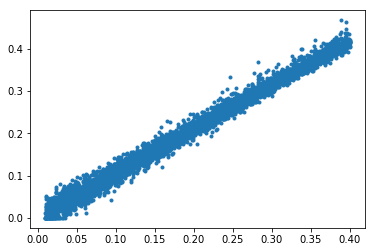

In [5]:
data = pandas.DataFrame({'ff_25' : ff_25, 'res_dixon_25' : res_dixon_25})
mod = smf.ols(formula='res_dixon_25 ~ ff_25', data=data)
res = mod.fit()
print(res.summary())
plt.plot(ff_25, res_dixon_25, '.')
plt.show()

print('\n')
print('###################################################################################')
print('\n')

data = pandas.DataFrame({'ff_25' : ff_25, 'res_tripl_25' : res_tripl_25})
mod = smf.ols(formula='res_tripl_25 ~ ff_25', data=data)
res = mod.fit()
print(res.summary())
plt.plot(ff_25, res_tripl_25, '.')
plt.show()

print('\n')
print('###################################################################################')
print('\n')

data = pandas.DataFrame({'ff_25' : ff_25, 'res_multi_25' : res_multi_25})
mod = smf.ols(formula='res_multi_25 ~ ff_25', data=data)
res = mod.fit()
print(res.summary())
plt.plot(ff_25, res_multi_25, '.')
plt.show()